In [97]:
!nvidia-smi

Sat Oct 17 10:37:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   67C    P0             30W /   70W |     223MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [98]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [106]:
import os
import pandas as pd

DATA_DIR = "/content/drive/MyDrive/HAM10000"

META_PATH = os.path.join(DATA_DIR, "HAM10000_metadata.csv")
TRAIN_PATH = os.path.join(DATA_DIR, "train_split.csv")
VAL_PATH = os.path.join(DATA_DIR, "val_split.csv")
TEST_PATH = os.path.join(DATA_DIR, "test_split.csv")

metadata = pd.read_csv(META_PATH)
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Metadata:", metadata.shape)
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain columns:", train_df.columns.tolist())
print("Validation columns:", val_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())

# Check image overlap between splits
train_ids = set(train_df["image_id"])
val_ids = set(val_df["image_id"])
test_ids = set(test_df["image_id"])

print("\nTrain-validation overlap:", len(train_ids & val_ids))
print("Train-test overlap:", len(train_ids & test_ids))
print("Validation-test overlap:", len(val_ids & test_ids))

print("\nClass distribution:")
print("Train:\n", train_df["dx"].value_counts().sort_index())
print("Validation:\n", val_df["dx"].value_counts().sort_index())
print("Test:\n", test_df["dx"].value_counts().sort_index())

Metadata: (10015, 7)
Train: (7991, 7)
Validation: (1008, 7)
Test: (1016, 7)

Train columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
Validation columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
Test columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

Class distribution:
Train:
 dx
akiec     260
bcc       424
bkl       856
df         97
mel       877
nv       5369
vasc      108
Name: count, dtype: int64
Validation:
 dx
akiec     26
bcc       36
bkl      133
df         8
mel      124
nv       663
vasc      18
Name: count, dtype: int64
Test:
 dx
akiec     41
bcc       54
bkl      110
df        10
mel      112
nv       673
vasc      16
Name: count, dtype: int64


In [107]:
import os
from glob import glob

IMAGE_DIRS = [
    os.path.join(DATA_DIR, "HAM10000_images_part_1"),
    os.path.join(DATA_DIR, "HAM10000_images_part_2"),
]

# Build image_id -> full image path mapping
image_paths = {}

for image_dir in IMAGE_DIRS:
    for path in glob(os.path.join(image_dir, "*.jpg")):
        image_id = os.path.splitext(os.path.basename(path))[0]
        image_paths[image_id] = path

print("Total JPG images found:", len(image_paths))

# Seven diagnostic classes
classes = sorted(train_df["dx"].unique())
class_to_idx = {label: idx for idx, label in enumerate(classes)}
idx_to_class = {idx: label for label, idx in class_to_idx.items()}

print("Classes:", classes)
print("Class-to-index mapping:", class_to_idx)

# Attach image paths and numeric labels
for df in [train_df, val_df, test_df]:
    df["image_path"] = df["image_id"].map(image_paths)
    df["label"] = df["dx"].map(class_to_idx)

# Check for missing images or labels
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        f"{name}: {len(df)} rows | "
        f"missing images: {df['image_path'].isna().sum()} | "
        f"missing labels: {df['label'].isna().sum()}"
    )

assert all(
    df["image_path"].notna().all()
    for df in [train_df, val_df, test_df]
), "Some images could not be located."

assert all(
    df["label"].notna().all()
    for df in [train_df, val_df, test_df]
), "Some labels could not be mapped."

Total JPG images found: 10015
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Class-to-index mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Train: 7991 rows | missing images: 0 | missing labels: 0
Validation: 1008 rows | missing images: 0 | missing labels: 0
Test: 1016 rows | missing images: 0 | missing labels: 0


In [108]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# ImageNet normalization for pretrained ResNet-50
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

# Create datasets
train_dataset = HAM10000Dataset(train_df, transform)
val_dataset = HAM10000Dataset(val_df, transform)
test_dataset = HAM10000Dataset(test_df, transform)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Device: cuda
Train batches: 250
Validation batches: 32
Test batches: 32


In [109]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in batch:", labels[:10].tolist())
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in batch: [4, 5, 5, 5, 5, 5, 5, 5, 5, 2]
Image dtype: torch.float32
Label dtype: torch.int64


In [110]:
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

# Load ResNet-50 pretrained on ImageNet
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

# Replace the final layer for HAM10000's 7 classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(classes))

# Move model to GPU/CPU
model = model.to(device)

print("Model: ResNet-50")
print("Pretrained: ImageNet")
print("Output classes:", model.fc.out_features)
print("Device:", device)

Model: ResNet-50
Pretrained: ImageNet
Output classes: 7
Device: cuda


In [111]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

EPOCHS = 10
best_val_loss = float("inf")

print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate:", 1e-4)
print("Epochs:", EPOCHS)

Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001
Epochs: 10


In [112]:
import copy
import torch

best_val_loss = float("inf")
best_epoch = 0
history = []

CHECKPOINT_PATH = "/content/best_resnet50_ham10000.pth"

for epoch in range(EPOCHS):
    # ---------- Training ----------
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ---------- Validation ----------
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    # Save the best model using validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": best_val_loss,
            "class_to_idx": class_to_idx
        }, CHECKPOINT_PATH)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Checkpoint saved to: {CHECKPOINT_PATH}")

Epoch [1/10] | Train Loss: 0.7432 | Train Acc: 0.7463 | Val Loss: 0.5616 | Val Acc: 0.7946
Epoch [2/10] | Train Loss: 0.3530 | Train Acc: 0.8741 | Val Loss: 0.4937 | Val Acc: 0.8304
Epoch [3/10] | Train Loss: 0.1596 | Train Acc: 0.9472 | Val Loss: 0.6129 | Val Acc: 0.8135
Epoch [4/10] | Train Loss: 0.0864 | Train Acc: 0.9720 | Val Loss: 0.6583 | Val Acc: 0.8125
Epoch [5/10] | Train Loss: 0.0701 | Train Acc: 0.9776 | Val Loss: 0.7983 | Val Acc: 0.8234
Epoch [6/10] | Train Loss: 0.0468 | Train Acc: 0.9842 | Val Loss: 0.8082 | Val Acc: 0.8145
Epoch [7/10] | Train Loss: 0.0393 | Train Acc: 0.9876 | Val Loss: 0.9289 | Val Acc: 0.7937
Epoch [8/10] | Train Loss: 0.0519 | Train Acc: 0.9829 | Val Loss: 0.7993 | Val Acc: 0.7877
Epoch [9/10] | Train Loss: 0.0398 | Train Acc: 0.9871 | Val Loss: 0.7681 | Val Acc: 0.8194
Epoch [10/10] | Train Loss: 0.0246 | Train Acc: 0.9934 | Val Loss: 0.9878 | Val Acc: 0.8046

Best epoch: 2
Best validation loss: 0.4937
Checkpoint saved to: /content/best_resnet50_h

In [113]:
import torch

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])

Loaded best epoch: 2
Best validation loss: 0.4937414581044799


In [114]:
import numpy as np
import torch

all_labels = []
all_preds = []
all_probs = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_preds.extend(predictions.cpu().numpy())
        all_probs.extend(probabilities.cpu().numpy())

y_true = np.array(all_labels)
y_pred = np.array(all_preds)
y_probs = np.array(all_probs)

print("Test samples:", len(y_true))
print("Prediction shape:", y_pred.shape)
print("Probability shape:", y_probs.shape)

Test samples: 1016
Prediction shape: (1016,)
Probability shape: (1016, 7)


In [115]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print(f"Test Accuracy:          {accuracy_score(y_true, y_pred):.4f}")
print(f"Balanced Accuracy:      {balanced_accuracy_score(y_true, y_pred):.4f}")
print(f"Macro F1-score:          {f1_score(y_true, y_pred, average='macro'):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(classes))),
        target_names=classes,
        digits=4,
        zero_division=0
    )
)

try:
    macro_auc = roc_auc_score(
        y_true,
        y_probs,
        multi_class="ovr",
        average="macro",
        labels=list(range(len(classes)))
    )
    print(f"Macro ROC-AUC (OvR):     {macro_auc:.4f}")
except ValueError as e:
    print("Macro ROC-AUC could not be calculated:", e)

Test Accuracy:          0.8307
Balanced Accuracy:      0.6504
Macro F1-score:          0.6542

Classification Report:
              precision    recall  f1-score   support

       akiec     0.5833    0.5122    0.5455        41
         bcc     0.7273    0.7407    0.7339        54
         bkl     0.7364    0.7364    0.7364       110
          df     0.2222    0.2000    0.2105        10
         mel     0.6176    0.5625    0.5888       112
          nv     0.9068    0.9257    0.9162       673
        vasc     0.8235    0.8750    0.8485        16

    accuracy                         0.8307      1016
   macro avg     0.6596    0.6504    0.6542      1016
weighted avg     0.8259    0.8307    0.8280      1016

Macro ROC-AUC (OvR):     0.9609


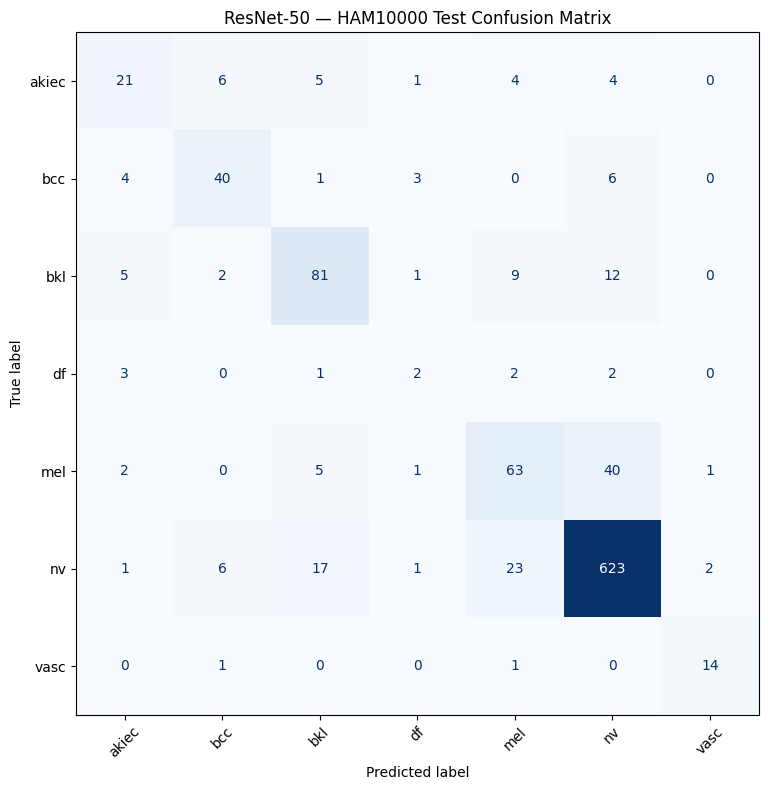

In [116]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title("ResNet-50 — HAM10000 Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [117]:
import os
import shutil

SAVE_DIR = "/content/drive/MyDrive/HAM10000_model"
os.makedirs(SAVE_DIR, exist_ok=True)

SOURCE_PATH = "/content/best_resnet50_ham10000.pth"
DEST_PATH = os.path.join(SAVE_DIR, "best_resnet50_ham10000.pth")

shutil.copy2(SOURCE_PATH, DEST_PATH)

print("Model saved successfully!")
print("Location:", DEST_PATH)
print("File size:", round(os.path.getsize(DEST_PATH) / (1024 * 1024), 2), "MB")

Model saved successfully!
Location: /content/drive/MyDrive/HAM10000_model/best_resnet50_ham10000.pth
File size: 269.64 MB


In [118]:
from google.colab import files

files.download("/content/drive/MyDrive/HAM10000_model/best_resnet50_ham10000.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>